# EDA básico

Por ahora se analiza el primer Parquet ordenado por nombre. Los conteos y faltantes usan todas las filas cargadas; el mapa usa una muestra aleatoria configurable con `FRACCION_MUESTRA`. Los resultados no representan todavía al dataset completo.

Solo se leen país y coordenadas, sin cargar imágenes. La misma muestra `df_muestra` queda disponible para otros análisis.

## Parte 1: EDA sobre los metadatos


In [11]:
# Configuración global de los análisis que utilizan una muestra.
FRACCION_MUESTRA = 1  # Porcentaje de todas las filas cargadas; cambiar aquí.
SEMILLA_MUESTRA = 42  # Permite reproducir el mismo subconjunto.

if not 0 < FRACCION_MUESTRA <= 1:
    raise ValueError("FRACCION_MUESTRA debe estar entre 0 (exclusivo) y 1.")


In [12]:
import os
from pathlib import Path

import pyarrow.parquet as pq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from IPython.display import display

# Buscar el .env desde la carpeta del notebook o la raíz del repositorio.
env_path = next(
    (folder / ".env" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / ".env").is_file()),
    None,
)
if env_path is None:
    raise FileNotFoundError("No se encontró el archivo .env del proyecto.")

# Cargar DATA_URL sin agregar dependencias al proyecto.
for line in env_path.read_text().splitlines():
    key, separator, value = line.partition("=")
    if separator and key.strip() == "DATA_URL":
        os.environ.setdefault("DATA_URL", value.strip().strip("\"'"))

DATA_URL = os.environ.get("DATA_URL", "")
if not DATA_URL:
    raise ValueError("Configurá DATA_URL en el archivo .env.")

data_dir = Path(DATA_URL).expanduser()
if not data_dir.is_absolute():
    data_dir = env_path.parent / data_dir
data_dir = data_dir.resolve()
if not data_dir.is_dir():
    raise NotADirectoryError(f"La carpeta de datos no existe: {data_dir}")

parquets = sorted(data_dir.glob("*.parquet"))
if not parquets:
    raise FileNotFoundError(f"No hay archivos Parquet en {data_dir}")

# Por ahora el alcance es únicamente el primer archivo.
archivos_eda = parquets[:1]
columnas_eda = ["country_code", "latitude", "longitude"]
df = pd.concat(
    [pq.read_table(archivo, columns=columnas_eda).to_pandas()
     for archivo in archivos_eda],
    ignore_index=True,
)
# Considerar cadenas vacías o con espacios como países faltantes.
df["country_code"] = df["country_code"].astype("string").str.strip().replace("", pd.NA)
total_filas = len(df)
if total_filas == 0:
    raise ValueError("El Parquet seleccionado no contiene filas.")
print(f"Archivos analizados: {len(archivos_eda):,}")
print(f"Filas analizadas: {total_filas:,}")
display(df.head())


Archivos analizados: 1
Filas analizadas: 5,087


,country_code,latitude,longitude
0,OM,23.537520,58.184800
1,OM,23.537520,58.184800
2,OM,23.537520,58.184800
3,OM,23.537520,58.184800
4,BR,-11.430396,-61.437989


In [13]:
# Muestra global compartida por los análisis que necesitan un subconjunto.
# Se muestrea sobre todas las filas, antes de excluir coordenadas inválidas.
df_muestra = df.sample(frac=FRACCION_MUESTRA, random_state=SEMILLA_MUESTRA).copy()
print(f"Muestra aleatoria configurada: {FRACCION_MUESTRA:.0%}")
print(f"Filas de la muestra: {len(df_muestra):,} de {total_filas:,} "
      f"({len(df_muestra) / total_filas:.2%} efectivo por redondeo)")


Muestra aleatoria configurada: 100%
Filas de la muestra: 5,087 de 5,087 (100.00% efectivo por redondeo)


## Los 10 países con más imágenes

El porcentaje se calcula sobre **todas las filas analizadas**, incluyendo aquellas sin país. Los países faltantes no compiten en el ranking. Cada fila representa una imagen; no se deduplican ubicaciones.


Los 10 países principales acumulan 65.17% de las imágenes analizadas.


,imagenes,porcentaje,porcentaje_acumulado
country_code,,,
US,1103,21.68,21.68
IN,728,14.31,35.99
BR,356,7.0,42.99
FR,244,4.8,47.79
TH,176,3.46,51.25
MX,152,2.99,54.24
RU,152,2.99,57.22
ID,140,2.75,59.98
CA,132,2.59,62.57


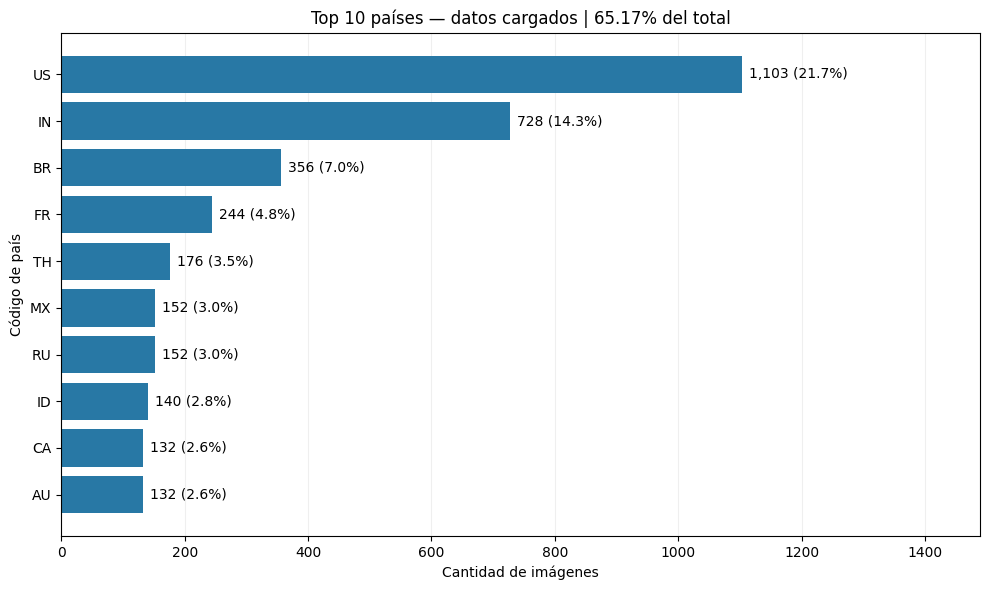

In [14]:
conteos_pais = df["country_code"].value_counts()
top10 = conteos_pais.head(10).rename_axis("country_code").to_frame("imagenes")
top10["porcentaje"] = top10["imagenes"] / total_filas * 100
top10["porcentaje_acumulado"] = top10["porcentaje"].cumsum()
porcentaje_top10 = top10["imagenes"].sum() / total_filas * 100
print(f"Los {len(top10)} países principales acumulan {porcentaje_top10:.2f}% de las imágenes analizadas.")
display(top10.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
if top10.empty:
    ax.text(0.5, 0.5, "No hay países informados", ha="center", transform=ax.transAxes)
else:
    barras = ax.barh(top10.index, top10["imagenes"], color="#2878a5")
    ax.invert_yaxis()
    ax.bar_label(barras, labels=[f"{n:,} ({pct:.1f}%)" for n, pct in
                                zip(top10["imagenes"], top10["porcentaje"])], padding=5)
    ax.set_xlim(0, top10["imagenes"].max() * 1.35)
ax.set(title=f"Top 10 países — datos cargados | {porcentaje_top10:.2f}% del total",
       xlabel="Cantidad de imágenes", ylabel="Código de país")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## Valores faltantes

Se cuentan nulos en las tres columnas y, para `country_code`, también códigos vacíos o con espacios. Los porcentajes usan todas las filas del archivo como denominador.


In [15]:
faltantes = df[columnas_eda].isna().sum().to_frame("faltantes")
faltantes["porcentaje"] = faltantes["faltantes"] / total_filas * 100
display(faltantes.round(2))
print(f"Filas con al menos un valor faltante: {df[columnas_eda].isna().any(axis=1).sum():,}")


,faltantes,porcentaje
country_code,32,0.63
latitude,0,0.00
longitude,0,0.00


Filas con al menos un valor faltante: 32


## Distribución geográfica por país

El mapa usa `df_muestra`: una muestra aleatoria de las filas cargadas, controlada por `FRACCION_MUESTRA` en la celda de configuración global. Cambiar esa variable y volver a ejecutar el notebook actualiza todos los análisis que usan esta muestra.

Dentro de la muestra, se muestran únicamente las filas con coordenadas válidas: latitud entre −90 y 90, longitud entre −180 y 180 y valores finitos. Los controles de coordenadas faltantes e inválidas se calculan sobre todos los datos cargados. Los puntos superpuestos se conservan.

Cada país tiene un color y una entrada en la leyenda; los países faltantes se muestran en negro. Con muchos países, algunos colores pueden resultar similares.

Mapa base local: [Natural Earth, países a escala 1:110m](https://github.com/nvkelso/natural-earth-vector/blob/master/geojson/ne_110m_admin_0_countries.geojson), datos de [dominio público](https://www.naturalearthdata.com/about/terms-of-use/). No se requiere conexión al ejecutar el notebook.


Filas con coordenadas faltantes: 0
Filas con coordenadas inválidas (sin faltantes): 0
Mapa: muestra aleatoria del 100% de los datos cargados (5,087 de 5,087 filas)
Puntos con coordenadas válidas: 5,087; excluidos de la muestra: 0


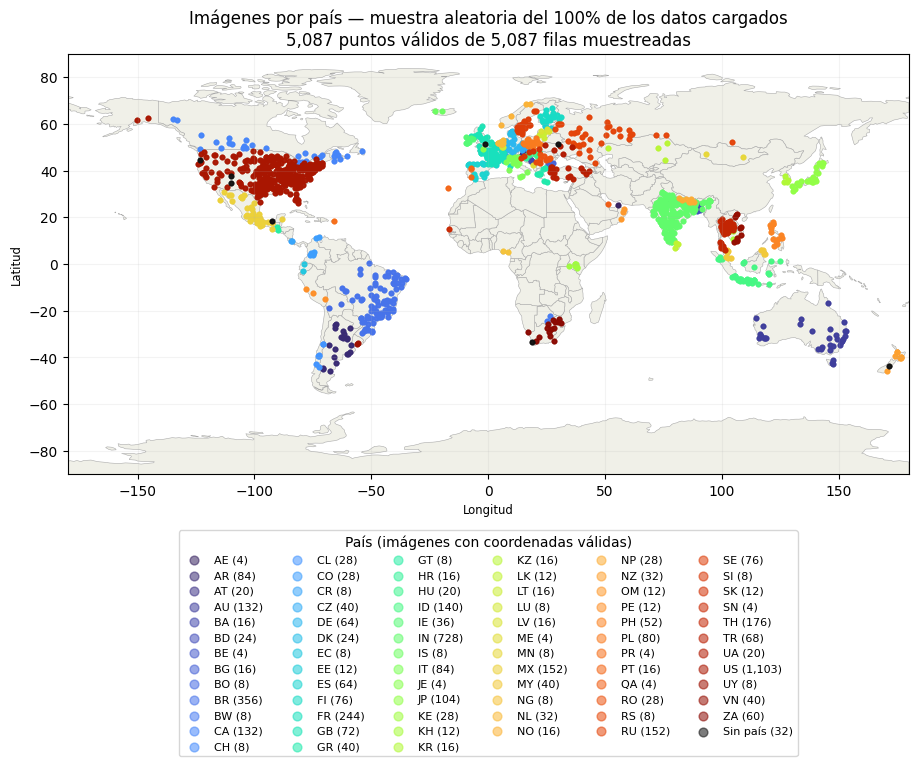

In [16]:
coordenadas = df[["latitude", "longitude"]]
coords_faltantes = coordenadas.isna().any(axis=1)
coords_validas = (
    np.isfinite(coordenadas).all(axis=1)
    & df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
)
coords_invalidas = ~coords_faltantes & ~coords_validas
print(f"Filas con coordenadas faltantes: {coords_faltantes.sum():,}")
print(f"Filas con coordenadas inválidas (sin faltantes): {coords_invalidas.sum():,}")
puntos = df_muestra.loc[coords_validas.reindex(df_muestra.index)].copy()
print(f"Mapa: muestra aleatoria del {FRACCION_MUESTRA:.0%} de los datos cargados "
      f"({len(df_muestra):,} de {total_filas:,} filas)")
print(f"Puntos con coordenadas válidas: {len(puntos):,}; "
      f"excluidos de la muestra: {len(df_muestra) - len(puntos):,}")

# Este GeoJSON se distribuye con el repositorio y es independiente del sistema operativo.
mapa_path = env_path.parent / "src" / "notebooks" / "eda" / "assets" / "ne_110m_admin_0_countries.geojson"
mundo = gpd.read_file(mapa_path).to_crs("EPSG:4326")
puntos["grupo_pais"] = puntos["country_code"].fillna("Sin país")
paises_mapa = sorted(puntos["country_code"].dropna().unique())

fig, ax = plt.subplots(figsize=(16, 8))
mundo.plot(ax=ax, color="#f0f0e8", edgecolor="#aaaaaa", linewidth=0.4)
paleta = plt.get_cmap("turbo")(np.linspace(0.02, 0.98, max(len(paises_mapa), 1)))
colores = dict(zip(paises_mapa, paleta))
colores["Sin país"] = "#111111"
for grupo in [*paises_mapa, "Sin país"]:
    subset = puntos.loc[puntos["grupo_pais"] == grupo]
    if not subset.empty:
        ax.scatter(subset["longitude"], subset["latitude"], s=10, alpha=0.55,
                   color=colores[grupo], label=f"{grupo} ({len(subset):,})", rasterized=True)
ax.set(xlim=(-180, 180), ylim=(-90, 90), xlabel="Longitud", ylabel="Latitud",
       title=f"Imágenes por país — muestra aleatoria del {FRACCION_MUESTRA:.0%} "
             f"de los datos cargados\n{len(puntos):,} puntos válidos de {len(df_muestra):,} filas muestreadas")
ax.set_aspect("equal")
ax.grid(alpha=0.15)
if not puntos.empty:
    ax.legend(title="País (imágenes con coordenadas válidas)", loc="upper center",
              bbox_to_anchor=(0.5, -0.12), ncol=6, fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()


### Paleta geográfica compartida

Los colores de todos los gráficos de imágenes se asignan por ubicación, independientemente del orden alfabético o de los países presentes en la muestra. Se toma un punto representativo de la mayor región de cada país en el mapa de Natural Earth.

Para conseguir mayor contraste se usa **HLS**: la longitud recorre el círculo de tonos, la latitud modifica la luminosidad y la saturación es alta. Así, Europa y Norteamérica tienen tonos distintos, mientras que países vecinos mantienen colores similares. El círculo de tonos es continuo al cruzar ±180°; la saturación disminuye hacia los polos, donde las longitudes convergen.

`SATURACION_GEOGRAFICA`, `LUMINOSIDAD_BASE` y `VARIACION_LUMINOSIDAD` permiten ajustar la intensidad. Esta paleta prioriza el contraste visual: no conserva exactamente distancias geográficas ni perceptuales. Un punto por país es una aproximación para países extensos o con territorios separados.

Si un código no está en el mapa, se usa el centro esférico de sus coordenadas válidas en los datos cargados y se informa. Sin ubicación se usa gris; sin país, negro. La paleta se define una sola vez en `COLORES_PAIS` y se ilustra en el mapa siguiente.


In [ ]:
# Paleta global de la Parte 2, independiente de las proyecciones de imágenes.
mapa_paleta_path = env_path.parent / "src" / "notebooks" / "eda" / "assets" / "ne_110m_admin_0_countries.geojson"
mundo_paleta = gpd.read_file(mapa_paleta_path).to_crs("EPSG:4326")

def vector_esferico(latitud, longitud):
    lat, lon = np.deg2rad(latitud), np.deg2rad(longitud)
    return np.array([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])

from colorsys import hls_to_rgb

SATURACION_GEOGRAFICA = 0.90  # Mayor valor: colores más intensos (0 a 1).
LUMINOSIDAD_BASE = 0.46
VARIACION_LUMINOSIDAD = 0.12

if not 0 <= SATURACION_GEOGRAFICA <= 1:
    raise ValueError("SATURACION_GEOGRAFICA debe estar entre 0 y 1.")
if not 0 <= VARIACION_LUMINOSIDAD <= min(LUMINOSIDAD_BASE, 1 - LUMINOSIDAD_BASE):
    raise ValueError("La luminosidad debe permanecer entre 0 y 1.")

def color_geografico(latitud, longitud):
    lat = np.deg2rad(latitud)
    tono = ((longitud + 180) / 360) % 1
    luminosidad = LUMINOSIDAD_BASE + VARIACION_LUMINOSIDAD * np.sin(lat)
    saturacion = SATURACION_GEOGRAFICA * np.cos(lat)
    return hls_to_rgb(tono, luminosidad, saturacion)

centros_paises = {}
for _, region in mundo_paleta.iterrows():
    codigo = region["ISO_A2_EH"]
    if not isinstance(codigo, str) or len(codigo) != 2 or region.geometry.is_empty:
        continue
    geometria = region.geometry
    if geometria.geom_type == "MultiPolygon":
        # Elegir la mayor parte por área en una proyección equivalente.
        partes = gpd.GeoSeries(list(geometria.geoms), crs="EPSG:4326")
        geometria = partes.iloc[int(np.argmax(partes.to_crs("EPSG:6933").area.to_numpy()))]
    centro = geometria.representative_point()
    centros_paises[codigo] = (centro.y, centro.x)

COLORES_PAIS = {codigo: color_geografico(*centro) for codigo, centro in centros_paises.items()}
COLORES_PAIS["Sin país"] = "#111111"
registros_paleta = []
for pais in sorted(df["country_code"].dropna().unique()):
    fuente = "Natural Earth"
    if pais not in centros_paises:
        coords = df.loc[df["country_code"].eq(pais), ["latitude", "longitude"]]
        coords = coords.loc[np.isfinite(coords).all(axis=1)
                            & coords["latitude"].between(-90, 90)
                            & coords["longitude"].between(-180, 180)]
        if not coords.empty:
            vector = vector_esferico(coords["latitude"].to_numpy(), coords["longitude"].to_numpy()).mean(axis=1)
            if np.linalg.norm(vector) > 1e-8:
                lat = np.rad2deg(np.arctan2(vector[2], np.hypot(vector[0], vector[1])))
                lon = np.rad2deg(np.arctan2(vector[1], vector[0]))
                centros_paises[pais] = (lat, lon)
                COLORES_PAIS[pais] = color_geografico(lat, lon)
        fuente = "Centro esférico de los datos" if pais in centros_paises else "Sin ubicación: gris"
        COLORES_PAIS.setdefault(pais, "#888888")
    lat, lon = centros_paises.get(pais, (np.nan, np.nan))
    registros_paleta.append({"country_code": pais, "latitude": lat, "longitude": lon, "fuente": fuente})
df_paleta = pd.DataFrame(registros_paleta, columns=["country_code", "latitude", "longitude", "fuente"])
print(f"Paleta geográfica lista para {len(df_paleta)} países de los datos cargados.")
alternativos = df_paleta.loc[df_paleta["fuente"] != "Natural Earth"]
if not alternativos.empty:
    display(alternativos)

fig, ax = plt.subplots(figsize=(16, 7))
from matplotlib.colors import to_rgba
colores_mundo = [to_rgba(COLORES_PAIS.get(codigo, "#dddddd"))
                 for codigo in mundo_paleta["ISO_A2_EH"]]
mundo_paleta.plot(ax=ax, color=colores_mundo, edgecolor="#888888", linewidth=0.4)
for registro in registros_paleta:
    if np.isfinite(registro["latitude"]):
        ax.text(registro["longitude"], registro["latitude"], registro["country_code"],
                ha="center", va="center", fontsize=6)
ax.set(title="Referencia de la paleta geográfica — colores compartidos por PCA y UMAP",
       xlim=(-180, 180), ylim=(-90, 90), xlabel="Longitud", ylabel="Latitud")
plt.tight_layout()
plt.show()


#### Referencia geográfica en cada gráfico

`agregar_planisferio(ax)` dibuja la misma paleta sobre un planisferio en la esquina superior derecha de cada eje, también en 3D. El argumento `posicion=(x, y, ancho, alto)` permite moverlo o cambiar su tamaño; los valores son fracciones del eje.


In [ ]:
def agregar_planisferio(ax, posicion=(0.66, 0.70, 0.32, 0.27)):
    """Añade una referencia de COLORES_PAIS; posición relativa al eje (x, y, ancho, alto).

    Funciona con ejes 2D y 3D. Devuelve el eje del mapa para personalizarlo.
    Ejemplo: agregar_planisferio(ax, posicion=(0.60, 0.67, 0.38, 0.31)).
    """
    from matplotlib.axes import Axes
    from matplotlib.colors import to_rgba

    # Reemplazar el mapa anterior si se vuelve a llamar sobre el mismo eje.
    for hijo in list(ax.child_axes):
        if hijo.get_label() == "referencia_geografica":
            hijo.remove()
    mapa_ax = ax.inset_axes(posicion, axes_class=Axes, zorder=10,
                            label="referencia_geografica")
    mapa_ax.set_facecolor("#ffffff")
    colores = [to_rgba(COLORES_PAIS.get(codigo, "#dddddd"))
               for codigo in mundo_paleta["ISO_A2_EH"]]
    mundo_paleta.plot(ax=mapa_ax, color=colores, edgecolor="#777777", linewidth=0.2)
    mapa_ax.set(xlim=(-180, 180), ylim=(-90, 90), xticks=[], yticks=[],
                xlabel="", ylabel="")
    mapa_ax.set_aspect("equal")
    mapa_ax.set_title("Referencia geográfica", fontsize=8, pad=3)
    for borde in mapa_ax.spines.values():
        borde.set_color("#bbbbbb")
        borde.set_linewidth(0.6)
    return mapa_ax


### PCA a dos componentes sobre la muestra

Se utilizan las mismas filas de `df_muestra`, controladas por `FRACCION_MUESTRA` y `SEMILLA_MUESTRA`. Cada imagen se convierte a **RGB**, se redimensiona a **64 × 64** y se normaliza a `[0, 1]`. Luego se aplana intercalando canales: `[R₁, G₁, B₁, R₂, G₂, B₂, …]`, obteniendo **12.288 variables por imagen**.

PCA centra cada variable y produce dos componentes. No se estandariza cada píxel por su desviación: se conserva la variación de intensidad. El país solo se usa para colorear el gráfico, no como entrada del PCA. Esta representación describe color, iluminación y composición; no equivale a una representación semántica.

Las imágenes se leen por lotes y solo se decodifican las filas seleccionadas. La matriz de píxeles de la muestra sí queda en memoria (aproximadamente 4,9 GB para 100.000 imágenes a 64 × 64 en `float32`). Las imágenes ausentes o ilegibles se excluyen y se reportan.


In [ ]:
from io import BytesIO
from PIL import Image, UnidentifiedImageError
from sklearn.decomposition import PCA

TAMANIO_IMAGEN = (64, 64)  # Ancho y alto; modificar para cambiar la resolución.
LOTE_IMAGENES = 32  # Limita los bytes de imágenes leídos simultáneamente.

indices_muestra = np.sort(df_muestra.index.to_numpy())
X_imagenes = np.empty((len(indices_muestra), np.prod(TAMANIO_IMAGEN) * 3), dtype=np.float32)
indices_imagenes = []
errores_imagenes = []
desplazamiento = 0

for archivo in archivos_eda:
    with pq.ParquetFile(archivo) as parquet:
        fin_archivo = desplazamiento + parquet.metadata.num_rows
        seleccion_archivo = indices_muestra[
            (indices_muestra >= desplazamiento) & (indices_muestra < fin_archivo)
        ]
        if len(seleccion_archivo):
            inicio_lote = desplazamiento
            for lote in parquet.iter_batches(batch_size=LOTE_IMAGENES, columns=["image"]):
                fin_lote = inicio_lote + lote.num_rows
                seleccion_lote = seleccion_archivo[
                    (seleccion_archivo >= inicio_lote) & (seleccion_archivo < fin_lote)
                ]
                for indice in seleccion_lote:
                    registro = lote.column(0)[int(indice - inicio_lote)].as_py()
                    try:
                        if registro is None:
                            raise ValueError("Imagen ausente")
                        contenido = registro.get("bytes")
                        if contenido is not None:
                            origen = BytesIO(contenido)
                        else:
                            ruta = registro.get("path")
                            if not ruta:
                                raise ValueError("Imagen sin bytes ni ruta")
                            origen = Path(ruta)
                            if not origen.is_absolute():
                                origen = archivo.parent / origen
                        with Image.open(origen) as imagen:
                            rgb = imagen.convert("RGB").resize(TAMANIO_IMAGEN, Image.Resampling.LANCZOS)
                            X_imagenes[len(indices_imagenes)] = (
                                np.asarray(rgb, dtype=np.float32).reshape(-1) / 255.0
                            )
                        indices_imagenes.append(int(indice))
                    except (OSError, ValueError, UnidentifiedImageError) as error:
                        errores_imagenes.append({"indice": int(indice), "error": str(error)})
                inicio_lote = fin_lote
        desplazamiento = fin_archivo

X_imagenes = X_imagenes[:len(indices_imagenes)]
df_imagenes = df.loc[indices_imagenes].copy()
print(f"Fracción de muestra: {FRACCION_MUESTRA:.1%}")
print(f"Imágenes procesadas: {len(df_imagenes):,} de {len(df_muestra):,} filas muestreadas")
print(f"Imágenes excluidas: {len(errores_imagenes):,}")
print(f"Matriz RGB: {X_imagenes.shape}; memoria: {X_imagenes.nbytes / 1024**2:.1f} MiB")
if errores_imagenes:
    display(pd.DataFrame(errores_imagenes).head(10))


In [ ]:
if len(X_imagenes) < 2:
    raise ValueError("Se necesitan al menos dos imágenes válidas para PCA.")
if not np.any(np.var(X_imagenes, axis=0) > 0):
    raise ValueError("Las imágenes no presentan variación para calcular PCA.")

pca_imagenes = PCA(n_components=2, svd_solver="randomized", random_state=SEMILLA_MUESTRA)
componentes = pca_imagenes.fit_transform(X_imagenes)
df_pca = df_imagenes.assign(PC1=componentes[:, 0], PC2=componentes[:, 1])
varianza = pca_imagenes.explained_variance_ratio_ * 100
print(f"Varianza explicada: PC1 = {varianza[0]:.2f}%; PC2 = {varianza[1]:.2f}%")
print(f"Varianza explicada acumulada: {varianza.sum():.2f}%")

paises_pca = sorted(df_pca["country_code"].dropna().unique())
colores_pca = COLORES_PAIS  # Paleta geográfica compartida por toda la Parte 2.
grupos_pca = df_pca["country_code"].fillna("Sin país")
fig, ax = plt.subplots(figsize=(14, 9))
for pais in [*paises_pca, "Sin país"]:
    grupo = df_pca.loc[grupos_pca == pais]
    if not grupo.empty:
        ax.scatter(grupo["PC1"], grupo["PC2"], color=colores_pca[pais], s=16,
                   alpha=0.6, label=f"{pais} ({len(grupo):,})", rasterized=True)
ax.set(xlabel=f"PC1 ({varianza[0]:.2f}% de varianza)",
       ylabel=f"PC2 ({varianza[1]:.2f}% de varianza)",
       title=f"PCA de imágenes RGB — muestra del {FRACCION_MUESTRA:.1%} de los datos cargados\n"
             f"{len(df_pca):,} imágenes válidas · resolución {TAMANIO_IMAGEN[0]} × {TAMANIO_IMAGEN[1]}")
ax.grid(alpha=0.2)
ax.legend(title="País (cantidad de imágenes)", loc="upper center",
          bbox_to_anchor=(0.5, -0.1), ncol=6, fontsize=8)
plt.tight_layout()
agregar_planisferio(ax)
plt.show()


### PCA a tres componentes

Se usa la misma matriz RGB y las mismas imágenes que en PCA 2D. Los ejes indican la varianza explicada y los colores por país se conservan entre gráficos.


In [ ]:
if min(X_imagenes.shape) < 3:
    raise ValueError("Se necesitan al menos tres imágenes válidas para PCA 3D.")
pca_imagenes_3d = PCA(n_components=3, svd_solver="randomized", random_state=SEMILLA_MUESTRA)
componentes_3d = pca_imagenes_3d.fit_transform(X_imagenes)
df_pca_3d = df_imagenes.assign(PC1=componentes_3d[:, 0], PC2=componentes_3d[:, 1], PC3=componentes_3d[:, 2])
varianza_3d = pca_imagenes_3d.explained_variance_ratio_ * 100
print("Varianza explicada:", ", ".join(f"PC{i+1}: {v:.2f}%" for i, v in enumerate(varianza_3d)))
print(f"Varianza explicada acumulada: {varianza_3d.sum():.2f}%")

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection="3d")
for pais in [*paises_pca, "Sin país"]:
    grupo = df_pca_3d.loc[grupos_pca == pais]
    if not grupo.empty:
        ax.scatter(grupo["PC1"], grupo["PC2"], grupo["PC3"], color=colores_pca[pais],
                   s=16, alpha=0.6, label=f"{pais} ({len(grupo):,})", rasterized=True)
ax.set(xlabel=f"PC1 ({varianza_3d[0]:.2f}%)", ylabel=f"PC2 ({varianza_3d[1]:.2f}%)",
       zlabel=f"PC3 ({varianza_3d[2]:.2f}%)",
       title=f"PCA 3D de imágenes RGB — muestra del {FRACCION_MUESTRA:.1%}\n"
             f"{len(df_pca_3d):,} imágenes · varianza acumulada: {varianza_3d.sum():.2f}%")
ax.legend(title="País (imágenes)", loc="upper center", bbox_to_anchor=(0.5, -0.05),
          ncol=6, fontsize=8)
plt.tight_layout()
agregar_planisferio(ax)
plt.show()


### UMAP a dos dimensiones

Se utiliza la misma muestra RGB, sin usar las etiquetas de país en el ajuste. Para reducir el costo, primero se comprime la matriz con PCA a un máximo de 50 componentes (**no** se parte del PCA 2D o 3D). Se informa la varianza retenida en ese paso.

`UMAP_VECINOS`, `UMAP_DISTANCIA_MINIMA` y `UMAP_COMPONENTES_PREVIAS` permiten ajustar el análisis. Se fija la semilla global para reproducibilidad. UMAP es no lineal: sus ejes no tienen porcentaje de varianza explicada y la separación visual no demuestra por sí sola diferencias entre países.

Referencia: [parámetros de UMAP](https://umap-learn.readthedocs.io/en/latest/parameters.html).


In [ ]:
from umap import UMAP

UMAP_VECINOS = 15
UMAP_DISTANCIA_MINIMA = 0.1
UMAP_COMPONENTES_PREVIAS = 50

if len(X_imagenes) < 4:
    raise ValueError("Se necesitan al menos cuatro imágenes válidas para este UMAP.")
if UMAP_VECINOS < 2 or UMAP_COMPONENTES_PREVIAS < 2:
    raise ValueError("Los vecinos y las componentes previas deben ser al menos 2.")
if not 0 <= UMAP_DISTANCIA_MINIMA <= 1:
    raise ValueError("UMAP_DISTANCIA_MINIMA debe estar entre 0 y 1.")
n_previo = min(UMAP_COMPONENTES_PREVIAS, len(X_imagenes) - 1, X_imagenes.shape[1])
pca_pre_umap = PCA(n_components=n_previo, svd_solver="randomized", random_state=SEMILLA_MUESTRA)
X_pre_umap = pca_pre_umap.fit_transform(X_imagenes)
print(f"PCA previo: {n_previo} componentes; "
      f"varianza retenida: {pca_pre_umap.explained_variance_ratio_.sum():.2%}")
vecinos_efectivos = min(UMAP_VECINOS, len(X_imagenes) - 1)
modelo_umap = UMAP(n_components=2, n_neighbors=vecinos_efectivos,
                   min_dist=UMAP_DISTANCIA_MINIMA, metric="euclidean",
                   random_state=SEMILLA_MUESTRA, n_jobs=1)
componentes_umap = modelo_umap.fit_transform(X_pre_umap)
df_umap = df_imagenes.assign(UMAP1=componentes_umap[:, 0], UMAP2=componentes_umap[:, 1])

fig, ax = plt.subplots(figsize=(14, 9))
for pais in [*paises_pca, "Sin país"]:
    grupo = df_umap.loc[grupos_pca == pais]
    if not grupo.empty:
        ax.scatter(grupo["UMAP1"], grupo["UMAP2"], color=colores_pca[pais], s=16,
                   alpha=0.6, label=f"{pais} ({len(grupo):,})", rasterized=True)
ax.set(xlabel="UMAP 1", ylabel="UMAP 2",
       title=f"UMAP de imágenes RGB — muestra del {FRACCION_MUESTRA:.1%}\n"
             f"{len(df_umap):,} imágenes · vecinos={vecinos_efectivos} · min_dist={UMAP_DISTANCIA_MINIMA}")
ax.grid(alpha=0.2)
ax.legend(title="País (imágenes)", loc="upper center", bbox_to_anchor=(0.5, -0.1),
          ncol=6, fontsize=8)
plt.tight_layout()
agregar_planisferio(ax)
plt.show()


### Color representativo de tres franjas horizontales: 9 dimensiones

Se reutilizan las imágenes RGB de la muestra, ya redimensionadas a 64 × 64 y normalizadas a `[0, 1]`. Cada imagen se divide de arriba hacia abajo en tres franjas de alturas lo más similares posible (22, 21 y 21 filas a esta resolución), sin descartar píxeles.

Por defecto se calcula la **media de cada canal RGB** dentro de cada franja: resume la composición global de color. La **mediana** es una alternativa menos sensible a píxeles extremos; se puede elegir con `RESUMEN_FRANJAS`.

El vector resultante es `[R_superior, G_superior, B_superior, R_media, G_media, B_media, R_inferior, G_inferior, B_inferior]`. PCA y UMAP usan directamente estas nueve variables, sin estandarización adicional ni PCA previo para UMAP. El país solo determina el color del gráfico.


In [ ]:
RESUMEN_FRANJAS = "media"  # Opciones: "media" o "mediana".

if RESUMEN_FRANJAS not in {"media", "mediana"}:
    raise ValueError('RESUMEN_FRANJAS debe ser "media" o "mediana".')
ancho, alto = TAMANIO_IMAGEN
if alto < 3:
    raise ValueError("La imagen debe tener al menos tres filas para crear las franjas.")
imagenes_rgb = X_imagenes.reshape(-1, alto, ancho, 3)
franjas_rgb = np.array_split(imagenes_rgb, 3, axis=1)
resumir = np.mean if RESUMEN_FRANJAS == "media" else np.median
X_franjas = np.concatenate(
    [resumir(franja, axis=(1, 2)) for franja in franjas_rgb], axis=1
).astype(np.float32)
columnas_franjas = [f"{franja}_{canal}" for franja in ["superior", "media", "inferior"]
                   for canal in ["R", "G", "B"]]
df_franjas = pd.DataFrame(X_franjas, index=df_imagenes.index, columns=columnas_franjas)
df_franjas["country_code"] = df_imagenes["country_code"]
print(f"Resumen: {RESUMEN_FRANJAS}; matriz: {X_franjas.shape}; "
      f"alturas de franjas: {[f.shape[1] for f in franjas_rgb]}")
display(df_franjas.head())


In [ ]:
from umap import UMAP

UMAP_FRANJAS_VECINOS = 15
UMAP_FRANJAS_DISTANCIA_MINIMA = 0.1

if len(X_franjas) < 4:
    raise ValueError("Se necesitan al menos cuatro imágenes para comparar PCA y UMAP.")
if not np.any(np.var(X_franjas, axis=0) > 0):
    raise ValueError("Los colores de las franjas no presentan variación.")
if UMAP_FRANJAS_VECINOS < 2 or not 0 <= UMAP_FRANJAS_DISTANCIA_MINIMA <= 1:
    raise ValueError("Revisá los vecinos (>=2) y min_dist (entre 0 y 1) de UMAP.")

pca_franjas = PCA(n_components=2, svd_solver="full")
componentes_pca_franjas = pca_franjas.fit_transform(X_franjas)
varianza_franjas = pca_franjas.explained_variance_ratio_ * 100
umap_franjas = UMAP(
    n_components=2, n_neighbors=min(UMAP_FRANJAS_VECINOS, len(X_franjas) - 1),
    min_dist=UMAP_FRANJAS_DISTANCIA_MINIMA, metric="euclidean",
    random_state=SEMILLA_MUESTRA, n_jobs=1,
)
componentes_umap_franjas = umap_franjas.fit_transform(X_franjas)
df_proyecciones_franjas = df_franjas.assign(
    PC1=componentes_pca_franjas[:, 0], PC2=componentes_pca_franjas[:, 1],
    UMAP1=componentes_umap_franjas[:, 0], UMAP2=componentes_umap_franjas[:, 1],
)
print(f"PCA de franjas: PC1 = {varianza_franjas[0]:.2f}%; "
      f"PC2 = {varianza_franjas[1]:.2f}%; acumulada = {varianza_franjas.sum():.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
grupos_franjas = df_franjas["country_code"].fillna("Sin país")
for pais in [*paises_pca, "Sin país"]:
    seleccion = grupos_franjas.eq(pais).to_numpy()
    if seleccion.any():
        for ax, proyeccion in zip(axes, [componentes_pca_franjas, componentes_umap_franjas]):
            ax.scatter(proyeccion[seleccion, 0], proyeccion[seleccion, 1],
                       color=colores_pca[pais], s=16, alpha=0.6,
                       label=f"{pais} ({seleccion.sum():,})", rasterized=True)
axes[0].set(title=f"PCA 2D · varianza acumulada: {varianza_franjas.sum():.2f}%",
            xlabel=f"PC1 ({varianza_franjas[0]:.2f}%)", ylabel=f"PC2 ({varianza_franjas[1]:.2f}%)")
axes[1].set(title=f"UMAP 2D · vecinos={umap_franjas.n_neighbors} · min_dist={UMAP_FRANJAS_DISTANCIA_MINIMA}",
            xlabel="UMAP 1", ylabel="UMAP 2")
for ax in axes:
    ax.grid(alpha=0.2)
fig.suptitle(f"Tres franjas horizontales · RGB por {RESUMEN_FRANJAS} · 9 variables\n"
             f"Muestra del {FRACCION_MUESTRA:.1%} · {len(X_franjas):,} imágenes válidas")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="País (imágenes)", loc="upper center",
           bbox_to_anchor=(0.5, 0), ncol=6, fontsize=8)
plt.tight_layout()
for ax in axes:
    agregar_planisferio(ax)
plt.show()
